# 2D calibration: fit a reduced window

The default loads the existing fit for the selected geometry, target and frequency window. Set RUN_CALIBRATION=True to fit new parameters; SAVE_DATA=True stores a new bare-parameter CSV. This workflow is independent of the waveguide analytical calibration.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


# Run 2D correction

Compute and save the bare parameters used by the 2D corrected simulation.

In [1]:
RUN_CALIBRATION = False
SAVE_DATA = False
SAVE_FIGURES = True  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"


import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np

resol = 300
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})


from importlib import import_module
bare_param_path = import_module("2d_setup.database").bare_param_path
load_bare_parameters_csv = import_module("2d_setup.database").load_bare_parameters_csv
read_metadata = import_module("2d_setup.database").read_metadata
save_bare_parameters_csv = import_module("2d_setup.database").save_bare_parameters_csv
target_profile_path = import_module("2d_setup.database").target_profile_path
get_2d_bare_parameters = import_module("2d_setup.bare_param").get_2d_bare_parameters
load_geometry_by_id = import_module("2d_setup.geometry").load_geometry_by_id

pi = np.pi

<h2>Load geometry</h2>

In [2]:
geometry_id = 5
geometry = load_geometry_by_id(geometry_id)

L1, L2 = geometry["lengths"]
N_A = geometry["N_A"]
atom_positions = geometry["atom_positions"]

print(f"Loaded geometry: {geometry['path'].name}")
print(f"lengths={geometry['lengths']}, N_A={N_A}, N_layer={geometry['N_layer']}, kind={geometry['kind']}")

Loaded geometry: geometry_id5.csv
lengths=[5. 5.], N_A=10, N_layer=1, kind=slab


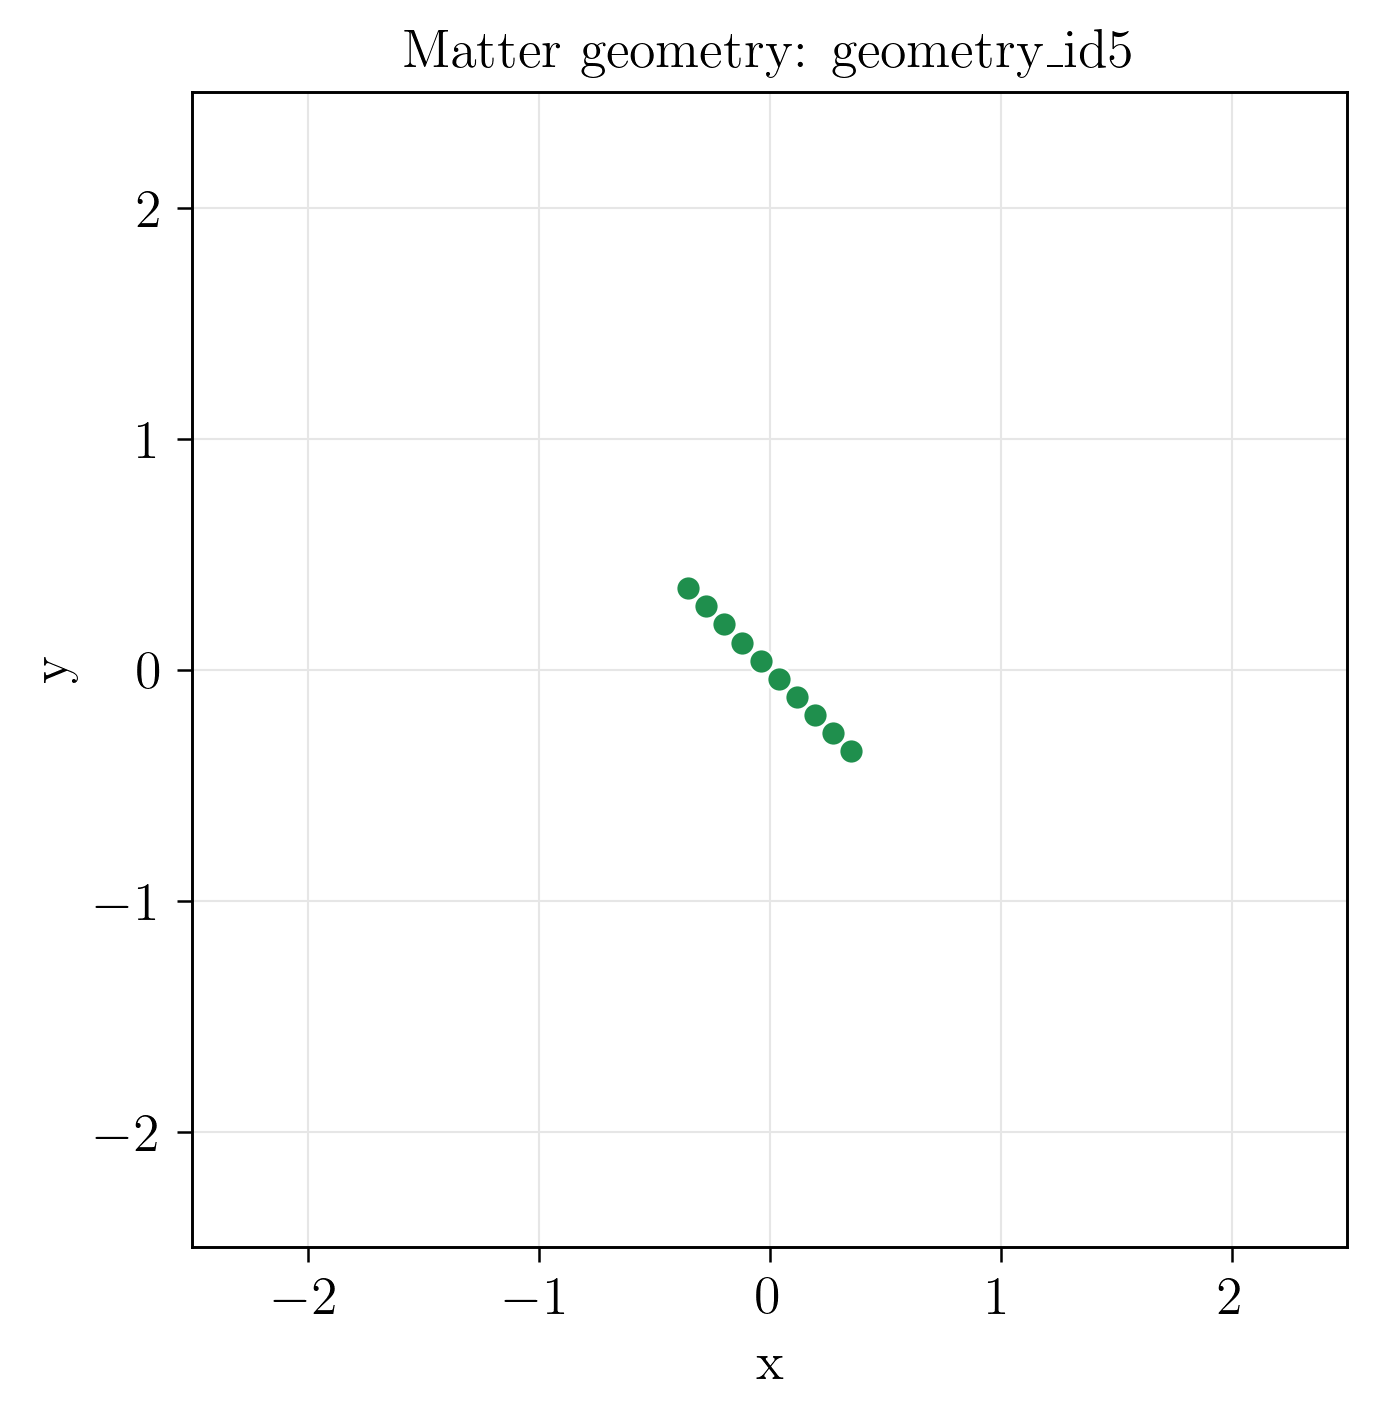

In [3]:
# Font sizes in points for this figure; edit these values directly.
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "legend.title_fontsize": 13,
})

fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
ax.scatter(
    atom_positions[:, 0],
    atom_positions[:, 1],
    s=34,
    color="#1f8f4d",
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)
ax.set_xlim(-L1 / 2, L1 / 2)
ax.set_ylim(-L2 / 2, L2 / 2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(color="0.9", linewidth=0.5)
ax.set_title(f"Matter geometry: {geometry['label']}")
plt.show()

<h2>Correction inputs</h2>

In [4]:
Omega_A_tab = 10 * np.pi * np.ones(N_A)
d_A_tab = np.ones(N_A, dtype=float)
id_target_profile = 1

cutoffs = {
    "Omega_min": 5 * np.pi,
    "Omega_max": 14 * np.pi,
}

target_profile_csv = target_profile_path(id_target_profile)

if not target_profile_csv.exists():
    raise FileNotFoundError(f"Missing target_profile_id{id_target_profile}.csv.")

target_metadata = read_metadata(target_profile_csv)
print(f"Target profile CSV: {target_profile_csv}")
print(f"Simulation window: [{cutoffs['Omega_min'] / np.pi:.6g} pi, {cutoffs['Omega_max'] / np.pi:.6g} pi]")

Target profile CSV: /Users/romainpiron/Documents/NII_local/light_matter_simu/single_photon_code/2d_setup/database_fiber/target_profiles/target_profile_id1.csv
Simulation window: [5 pi, 14 pi]


<h2>Run optimization</h2>

In [5]:
if RUN_CALIBRATION:
    Omega_0_tab, d_0_tab = get_2d_bare_parameters(
        target_profile_csv,
        atom_positions,
        cutoffs,
    )

    print(f"Omega_0/pi range: {np.min(Omega_0_tab) / np.pi:.6g} -- {np.max(Omega_0_tab) / np.pi:.6g}")
    print(f"d_0 range: {np.min(d_0_tab):.6g} -- {np.max(d_0_tab):.6g}")
else:
    from importlib import import_module
    find_bare_param_path = import_module("2d_setup.database").find_bare_param_path
    fit_path = find_bare_param_path(Omega_A_tab, d_A_tab, cutoffs, id_geom=geometry_id, id_target_profile=id_target_profile)
    Omega_0_tab, d_0_tab = load_bare_parameters_csv(fit_path)
    print(f"Loaded existing calibration: {fit_path.name}")

Loaded existing calibration: bare_param_id4.csv


<h2>Save bare parameters</h2>

In [6]:
if SAVE_DATA and RUN_CALIBRATION:
    output_path = bare_param_path()
    save_bare_parameters_csv(Omega_0_tab, d_0_tab, target_metadata, cutoffs, output_path)

    print(f"Saved bare parameters to: {output_path}")
else:
    print("No calibration written. Enable RUN_CALIBRATION and SAVE_DATA to save a new fit.")

No calibration written. Enable RUN_CALIBRATION and SAVE_DATA to save a new fit.


<h2>Plot bare parameters</h2>

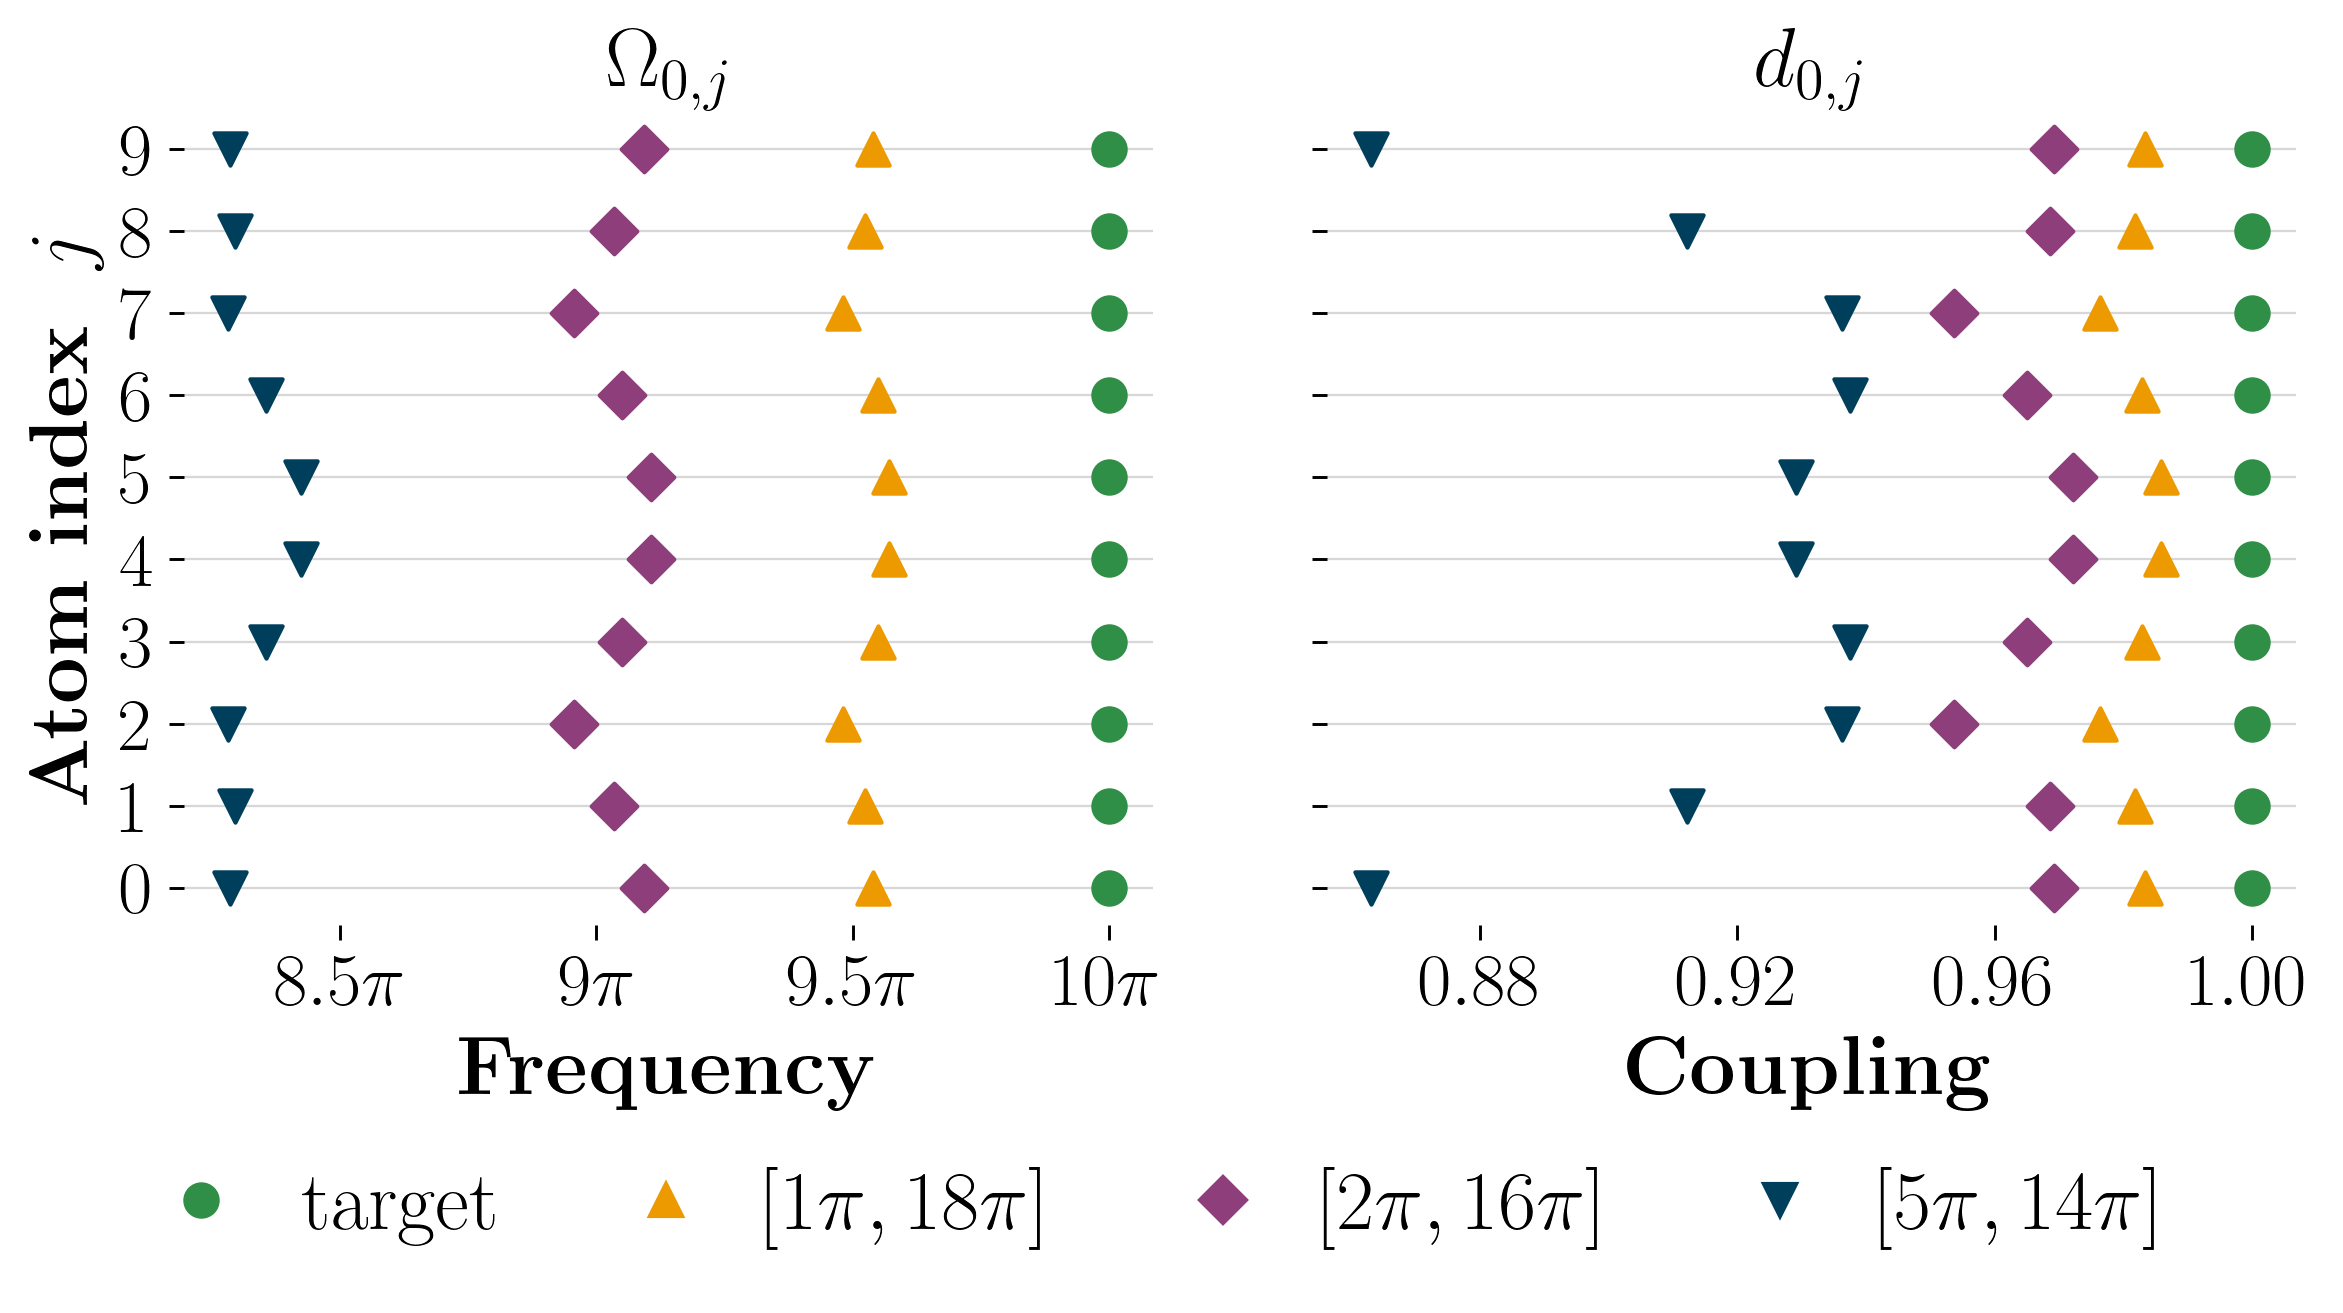

Saved figure to: /Users/romainpiron/Documents/NII_local/light_matter_simu/single_photon_code/2d_setup/results/fig/bare_parameters_freqwindows_2d.pdf


In [17]:
# Font sizes in points for this figure; edit these values directly.
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
})

bare_param_id_to_plot = [2, 3, 4]

target_color = "#2f8f46"
window_colors = ["#111111", "#ed9a00", "#8e3e7a", "#003f5c"]
window_color_by_pi = {
    (0, 20): window_colors[0],
    (1, 18): window_colors[1],
    (2, 16): window_colors[2],
    (5, 14): window_colors[3],
}

window_markers = ["s", "^", "D", "v", "P", "X", "<", ">", "h", "*"]
window_marker_by_pi = dict(zip(window_color_by_pi, window_markers))
marker_size = 60

bare_param_ids = np.atleast_1d(bare_param_id_to_plot).astype(int).tolist()
bare_param_sets = []

for bare_param_id in bare_param_ids:
    bare_param_csv = bare_param_path(bare_param_id)
    if not bare_param_csv.exists():
        raise FileNotFoundError(f"Missing bare_param_id{bare_param_id}.csv.")

    metadata = read_metadata(bare_param_csv)
    Omega_0, d_0 = load_bare_parameters_csv(bare_param_csv)
    ir_pi = metadata["Omega_min"] / pi
    uv_pi = metadata["Omega_max"] / pi
    window_key = (int(round(ir_pi)), int(round(uv_pi)))
    color = window_color_by_pi.get(window_key, window_colors[(len(bare_param_sets) + 1) % len(window_colors)])
    marker = window_marker_by_pi.setdefault(
        window_key, window_markers[len(window_marker_by_pi) % len(window_markers)]
    )
    label = rf"$[{ir_pi:.0f}\pi,{uv_pi:.0f}\pi]$"

    bare_param_sets.append({
        "id": bare_param_id,
        "metadata": metadata,
        "Omega_0": Omega_0,
        "d_0": d_0,
        "color": color,
        "marker": marker,
        "label": label,
    })

n_atoms = {len(param_set["Omega_0"]) for param_set in bare_param_sets}
if len(n_atoms) != 1:
    raise ValueError("All plotted bare-parameter sets must have the same number of atoms.")

omega_targets = [param_set["metadata"]["Omega_A"] for param_set in bare_param_sets]
d_targets = [param_set["metadata"]["d_A"] for param_set in bare_param_sets]
if not all(np.allclose(omega_targets[0], omega_target) for omega_target in omega_targets[1:]):
    raise ValueError("All plotted bare-parameter sets must share the same target Omega_A.")
if not all(np.allclose(d_targets[0], d_target) for d_target in d_targets[1:]):
    raise ValueError("All plotted bare-parameter sets must share the same target d_A.")

N_A = n_atoms.pop()
atom_index = np.arange(N_A)
omega_target = omega_targets[0] / pi
d_target = d_targets[0]

def pi_formatter(value, _):
    if np.isclose(value, 0):
        return "0"
    if np.isclose(value, 1):
        return r"$\pi$"
    if np.isclose(value, -1):
        return r"$-\pi$"
    if np.isclose(value, round(value)):
        return rf"${int(round(value))}\pi$"
    return rf"${value:.1f}\pi$"

fig, (omega_ax, d_ax) = plt.subplots(
    1,
    2,
    figsize=(8, max(3.8, 0.28 * N_A + 1.5)),
    dpi=resol,
    sharey=True,
    gridspec_kw={"wspace": 0.18},
)

for param_set in reversed(bare_param_sets):
    omega_bare = param_set["Omega_0"] / pi
    d_bare = param_set["d_0"]
    omega_ax.scatter(
        omega_bare, atom_index, color=param_set["color"],
        marker=param_set["marker"], s=marker_size, zorder=4,
    )
    d_ax.scatter(
        d_bare, atom_index, color=param_set["color"],
        marker=param_set["marker"], s=marker_size, zorder=4,
    )

omega_ax.scatter(omega_target, atom_index, color=target_color, marker="o", s=marker_size, zorder=5)
d_ax.scatter(d_target, atom_index, color=target_color, marker="o", s=marker_size, zorder=5)

for ax in (omega_ax, d_ax):
    ax.set_yticks(atom_index)
    ax.set_yticklabels([rf"${j}$" for j in atom_index])
    ax.invert_yaxis()
    ax.yaxis.grid(which="major", linestyle="-", linewidth=0.55, color="0.78", alpha=0.7)
    ax.xaxis.grid(False)
    ax.tick_params(axis="both", which="major", length=3.5, width=0.7, labelsize=18)
    for spine in ax.spines.values():
        spine.set_visible(False)

omega_ax.set_title(r" $\Omega_{0,j}$", fontsize=20, fontweight="bold")
omega_ax.set_xlabel(r"\textbf{Frequency}", fontsize=20)
omega_ax.set_ylabel(r"\textbf{Atom index } $j$", fontsize=20)
omega_ticks = np.arange(
    np.ceil(min(omega_target.min(), *(param_set["Omega_0"].min() / pi for param_set in bare_param_sets)) * 2) / 2,
    np.floor(max(omega_target.max(), *(param_set["Omega_0"].max() / pi for param_set in bare_param_sets)) * 2) / 2 + 0.25,
    0.5,
)
omega_ax.set_xticks(omega_ticks)
omega_ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))

d_ax.set_title(r"$d_{0,j}$", fontsize=20, fontweight="bold")
d_ax.set_xlabel(r"\textbf{Coupling}", fontsize=20)
d_ax.xaxis.set_major_locator(MaxNLocator(nbins=5))

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color=target_color,
        linestyle="none",
        markersize=np.sqrt(marker_size),
        label=r"target",
    ),
    *(
        Line2D(
            [0],
            [0],
            marker=param_set["marker"],
            color=param_set["color"],
            linestyle="none",
            markersize=np.sqrt(marker_size),
            label=param_set["label"],
        )
        for param_set in bare_param_sets
    ),
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.06),
    ncol=min(len(legend_handles), 4),
    frameon=False,
    fontsize=20,
    columnspacing=1.0,  
    handletextpad=0.2,  
)

fig.subplots_adjust(left=0.10, right=0.98, bottom=0.25, top=0.88, wspace=0.22)
figure_path = setup_root / "results" / "fig" / "bare_parameters_freqwindows_2d.pdf"
figure_path.parent.mkdir(parents=True, exist_ok=True)
if SAVE_FIGURES:
    plt.savefig(figure_path, dpi=resol, bbox_inches="tight")
plt.show()
if SAVE_FIGURES:
    print(f"Saved figure to: {figure_path}")